# Chapitre 2 - Cours 5 : triplets, SPARQL et Datalog

Le cours 4 a présenté le graphe de propriétés et Cypher. Ce cours explore l'autre grande
famille, les **magasins de triplets** et leur langage SPARQL, puis **Datalog**, le plus
ancien et le plus expressif des langages de requêtes récursives, qui fonde tous les
autres. Il couvre les sections *Triple-Stores and SPARQL* (*The semantic web*, *The RDF
data model*, *The SPARQL query language*, encadré *Graph Databases Compared to the
Network Model*) et *The Foundation: Datalog*.

**Plan.**

1. Tout est triplet : sujet, prédicat, objet.
2. Le Web sémantique et le modèle RDF.
3. SPARQL : motifs et chemins de propriétés.
4. Les bases de graphes face au modèle réseau.
5. Datalog : des faits et des règles.
6. Évaluer Datalog : naïf contre semi-naïf.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Tout est triplet : sujet, prédicat, objet (section *Triple-Stores and SPARQL*)

Le modèle du **magasin de triplets** dit presque la même chose que le graphe de
propriétés, avec d'autres mots. Toute l'information y est rangée en énoncés très
simples à trois parties, **(sujet, prédicat, objet)** : dans (Inès, aime, la poutine),
Inès est le sujet, « aime » le prédicat (le verbe) et la poutine l'objet.

Le sujet est toujours un sommet. L'objet est l'une de deux choses :

- une **valeur primitive** (chaîne, nombre) : prédicat et objet jouent alors le rôle
  de la clé et de la valeur d'une **propriété** du sujet. (ines, birthYear, 1988)
  équivaut au sommet `ines` avec la propriété `{"birthYear": 1988}` ;
- un **autre sommet** : le prédicat est alors une **arête**, de la queue (le sujet) vers
  la tête (l'objet). (ines, livesIn, montreal) est l'arête `LIVES_IN`.

`dm.graph_to_triples` traduit notre graphe de propriétés en triplets ; voici la
sérialisation au format **Turtle** (un sous-ensemble de Notation3), où `_:nom` désigne un
sommet anonyme, `a` abrège « est de type », et le point-virgule enchaîne plusieurs
énoncés sur le même sujet.

In [2]:
g = dm.example_graph()
ts = dm.graph_to_triples(g)
print(f"{len(ts)} triplets\n")
print(ts.to_turtle())

70 triplets

@prefix : <urn:example:>.
_:europe a :Location; :name "Europe"; :type "continent".
_:amnord a :Location; :name "Amérique du Nord"; :type "continent".
_:asie a :Location; :name "Asie"; :type "continent".
_:france a :Location; :name "France"; :type "pays"; :within _:europe.
_:canada a :Location; :name "Canada"; :type "pays"; :within _:amnord.
_:japon a :Location; :name "Japon"; :type "pays"; :within _:asie.
_:aura a :Location; :name "Auvergne-Rhône-Alpes"; :type "région"; :within _:france.
_:bretagne a :Location; :name "Bretagne"; :type "région"; :within _:france.
_:rhone a :Location; :name "Rhône"; :type "département"; :within _:aura.
_:lyon a :Location; :name "Lyon"; :type "ville"; :within _:rhone.
_:quebec a :Location; :name "Québec"; :type "province"; :within _:canada.
_:montreal a :Location; :name "Montréal"; :type "ville"; :within _:quebec.
_:kansai a :Location; :name "Kansai"; :type "région"; :within _:japon.
_:osaka a :Location; :name "Osaka"; :type "ville"; :within 

Un magasin de triplets doit répondre à des motifs où n'importe lequel des trois termes
peut être inconnu : « tous les prédicats de Lyon » `(lyon, ?, ?)`, « tous les sujets nés à
Lyon » `(?, bornIn, lyon)`, « tout ce qui pointe vers Montréal » `(?, ?, montreal)`. Notre
`TripleStore` tient pour cela **trois index** (SPO, POS, OSP) : chaque forme de motif
trouve un index dont le préfixe correspond aux termes connus.

In [3]:
motifs = [("_:lyon", None, None), ("_:lyon", "within", None), (None, "bornIn", "_:lyon"),
          (None, "bornIn", None), (None, None, "_:montreal"), ("_:ines", None, "_:montreal")]
def index_used(s, p, o):
    return "SPO" if s is not None else ("POS" if p is not None else ("OSP" if o is not None else "parcours complet"))
show = lambda t: "?" if t is None else t
pd.DataFrame({"motif": [f"({show(s)}, {show(p)}, {show(o)})" for s, p, o in motifs],
              "index utilisé": [index_used(*m) for m in motifs],
              "réponses": [", ".join(f"({a}, {b}, {c})" for a, b, c in ts.match(*m))[:85] for m in motifs]})

,motif,index utilisé,réponses
0,"(_:lyon, ?, ?)",SPO,"(_:lyon, a, Location), (_:lyon, name, Lyon), (_:lyon, type, ville), (_:lyon, within,"
1,"(_:lyon, within, ?)",SPO,"(_:lyon, within, _:rhone)"
2,"(?, bornIn, _:lyon)",POS,"(_:ines, bornIn, _:lyon)"
3,"(?, bornIn, ?)",POS,"(_:ines, bornIn, _:lyon), (_:kenji, bornIn, _:osaka), (_:lea, bornIn, _:bretagne)"
4,"(?, ?, _:montreal)",OSP,"(_:ines, livesIn, _:montreal), (_:kenji, livesIn, _:montreal)"
5,"(_:ines, ?, _:montreal)",SPO,"(_:ines, livesIn, _:montreal)"


> **À retenir.** Un magasin de triplets range tout en (sujet, prédicat, objet). Un objet
> littéral fait du triplet une propriété, un objet sommet en fait une arête : le modèle
> est équivalent au graphe de propriétés. Trois index (SPO, POS, OSP) servent tous les
> motifs.

## 2. Le Web sémantique et le modèle RDF (sous-sections *The semantic web* et *The RDF data model*)

Une partie du travail sur les triplets vient du **Web sémantique**, un projet du début
des années 2000 : publier sur le Web non seulement des pages pour les humains mais aussi
des données dans un format standard lisible par les machines, pour que des sites
différents puissent combiner leurs informations. Le projet n'a pas tenu toutes ses
promesses. Les triplets restent un bon **modèle interne** pour une
application, même sans aucun intérêt pour le Web sémantique.

Le format Turtle encode des données du modèle **RDF** (*Resource Description
Framework*), conçu pour cet échange à l'échelle d'Internet. D'où une particularité : les
sujets, prédicats et objets sont souvent des **URI**, comme
`<http://mon-entreprise.example/ns#within>`. Si quelqu'un d'autre donne un autre sens au
mot `within`, ses prédicats auront un autre préfixe et les deux jeux de données se
combineront **sans conflit**. L'URI n'a pas besoin de mener à une vraie page : c'est un
simple **espace de noms**, déclaré une fois en tête de fichier (`@prefix`).

Démonstration : fusionnons notre graphe avec celui d'une agence de voyages, pour qui
`within` signifie « séjour compris dans un forfait ».

In [4]:
agence = [("_:sejour_montreal", "within", "_:forfait_canada"), ("_:sejour_montreal", "name", "Montréal"),
          ("_:forfait_canada", "name", "Canada")]
naif = dm.TripleStore()
for s, p, o in ts.match():
    naif.add(s, p, o)
for t in agence:
    naif.add(*t)
ns = dm.TripleStore()
for s, p, o in ts.match():
    ns.add(s, p if p == "a" else "<urn:geo:" + p + ">", o)
for s, p, o in agence:
    ns.add(s, "<urn:voyage:" + p + ">", o)
q_naif = sorted(naif.path_subjects("Canada", ("within*", "name")))
q_ns = sorted(ns.path_subjects("Canada", ("<urn:geo:within>*", "<urn:geo:name>")))
pd.DataFrame({"fusion": ["prédicats nus", "prédicats dans un espace de noms"],
              "« ce qui est situé au Canada »": [", ".join(q_naif), ", ".join(q_ns)]})

,fusion,« ce qui est situé au Canada »
0,prédicats nus,"_:canada, _:forfait_canada, _:montreal, _:quebec, _:sejour_montreal"
1,prédicats dans un espace de noms,"_:canada, _:montreal, _:quebec"


Avec des prédicats nus, la requête géographique ramène un **forfait de voyage** comme
s'il était un lieu du Canada ; avec des espaces de noms, chaque `within` garde son sens.
Les données RDF peuvent aussi s'encoder en XML (RDF/XML), de façon bien plus verbeuse, et
des outils comme Apache Jena convertissent d'un encodage à l'autre.

> **À retenir.** RDF est le modèle de triplets du Web sémantique ; ses termes sont des
> URI pour que des jeux de données indépendants se combinent sans collision de noms.
> Turtle en est un encodage lisible.

## 3. SPARQL : motifs et chemins de propriétés (sous-section *The SPARQL query language*)

**SPARQL** (acronyme récursif de *SPARQL Protocol and RDF Query Language*, prononcé
« sparkle ») interroge les magasins de triplets RDF. Il est antérieur à Cypher, qui lui a
emprunté son filtrage par motifs ; les deux se ressemblent beaucoup. Notre question
« nés en Europe, vivant en Amérique du Nord » s'écrit :

```sparql
PREFIX : <urn:example:>
SELECT ?personName WHERE {
  ?person :name ?personName.
  ?person :bornIn  / :within* / :name "Europe".
  ?person :livesIn / :within* / :name "Amérique du Nord".
}
```

`?x` est une variable ; `:bornIn / :within* / :name` est un **chemin de propriétés** :
suivre `bornIn`, puis `within` zéro fois ou plus, puis `name`. Correspondances :

| Cypher | SPARQL |
|---|---|
| `(person) -[:BORN_IN]-> () -[:WITHIN*0..]-> (location)` | `?person :bornIn / :within* ?location.` |
| `(usa {name:'Canada'})` | `?usa :name "Canada".` |

RDF ne distinguant pas propriétés et arêtes (tout est prédicat), la même syntaxe sert
aux deux. Notre `TripleStore.query` évalue ces motifs (un tuple de prédicats représente
un chemin, `p*` l'étoile) :

In [5]:
sols = ts.query([
    ("?person", "name", "?personName"),
    ("?person", ("bornIn", "within*", "name"), "Europe"),
    ("?person", ("livesIn", "within*", "name"), "Amérique du Nord"),
])
[s["?personName"] for s in sols]

['Inès']

Notre moteur joint les motifs **dans l'ordre écrit**, sans optimiseur. L'ordre a pourtant
un énorme effet sur le travail : commencer par un motif sélectif réduit toutes les
étapes suivantes. Mesurons-le sur le graphe synthétique du cours 4 traduit en triplets,
avec la question « qui vit dans la région 2.1.3 et est né en Asie ? ».

In [6]:
world = dm.make_world_graph(n_people=20_000, seed=1)
wts = dm.graph_to_triples(world)
print(f"{fmt(len(wts))} triplets")
ordres = {
    "personnes d'abord": [("?p", "a", "Person"), ("?p", ("livesIn", "within*", "name"), "Région 2.1.3"),
                          ("?p", ("bornIn", "within*", "name"), "Asie")],
    "naissance d'abord": [("?p", ("bornIn", "within*", "name"), "Asie"), ("?p", "a", "Person"),
                          ("?p", ("livesIn", "within*", "name"), "Région 2.1.3")],
    "résidence d'abord": [("?p", ("livesIn", "within*", "name"), "Région 2.1.3"),
                          ("?p", ("bornIn", "within*", "name"), "Asie"), ("?p", "a", "Person")],
}
rows, stats_all = [], {}
for k, q in ordres.items():
    st = []
    t0 = time.perf_counter(); r = wts.query(q, st); dt = time.perf_counter() - t0
    stats_all[k] = st
    rows.append({"ordre des motifs": k, "solutions": len(r), "solutions partielles": sum(st), "ms": dt * 1e3})
assert len({r["solutions"] for r in rows}) == 1
pd.DataFrame(rows)

92 882 triplets


,ordre des motifs,solutions,solutions partielles,ms
0,personnes d'abord,7,20052,57.947
1,naissance d'abord,7,13197,22.731
2,résidence d'abord,7,59,0.148


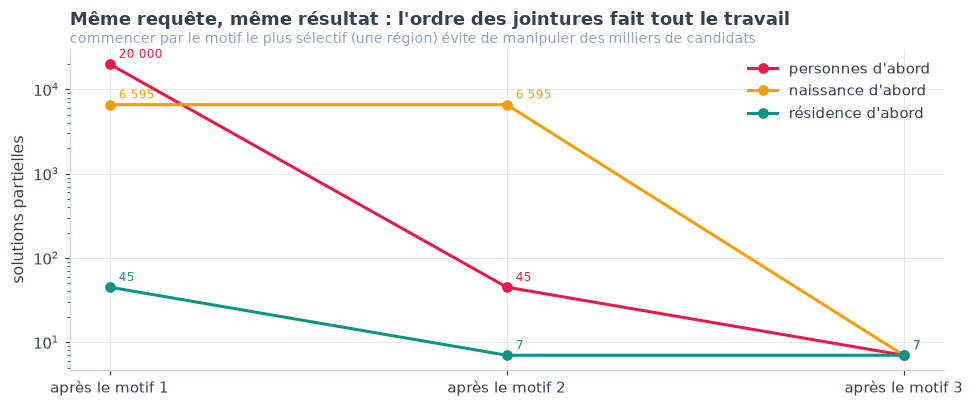

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for (k, st), col in zip(stats_all.items(), [ROSE, AMBER, TEAL]):
    ax.plot([1, 2, 3], st, marker="o", color=col, label=k)
    for i, v in enumerate(st):
        ax.annotate(fmt(v), (i + 1, v), (6, 4), textcoords="offset points", fontsize=8, color=col)
ax.set_yscale("log"); ax.set_xticks([1, 2, 3], ["après le motif 1", "après le motif 2", "après le motif 3"])
ax.set_ylabel("solutions partielles")
ax.set_title("Même requête, même résultat : l'ordre des jointures fait tout le travail")
subtitle(ax, "commencer par le motif le plus sélectif (une région) évite de manipuler des milliers de candidats")
ax.legend(); plt.tight_layout(); plt.show()

Le résultat est identique, mais commencer par toutes les personnes manipule des dizaines
de milliers de solutions partielles, quand commencer par la région n'en manipule qu'une
poignée. Un vrai moteur SPARQL choisit cet ordre à partir de statistiques ; c'est le
bénéfice du déclaratif, déjà rencontré avec SQL et Cypher. SPARQL est disponible dans de
nombreux magasins de triplets (Apache Jena, Virtuoso, AllegroGraph, Blazegraph...).

> **À retenir.** SPARQL filtre par motifs de triplets avec des variables et des chemins
> de propriétés (`:within*`), d'une concision comparable à Cypher. L'ordre d'évaluation
> des motifs change le travail de plusieurs ordres de grandeur : c'est l'affaire de
> l'optimiseur.

## 4. Les bases de graphes face au modèle réseau (encadré *Graph Databases Compared to the Network Model*)

Le cours 2 a présenté le modèle réseau de CODASYL. Les bases de graphes sont-elles un
retour de CODASYL sous un nouveau nom ? Non, répond le livre, pour quatre raisons :

In [8]:
pd.DataFrame({
    "question": ["quels liens sont permis ?", "comment atteindre un enregistrement ?",
                 "les liens sont-ils ordonnés ?", "comment interroge-t-on ?"],
    "modèle réseau (CODASYL)": [
        "un schéma fixe dit quel type d'enregistrement peut être imbriqué dans quel autre",
        "seulement en suivant un chemin d'accès depuis une racine",
        "oui : les enfants d'un enregistrement forment une liste ordonnée que la base doit maintenir",
        "uniquement par navigation impérative, écrite à la main"],
    "base de graphes": [
        "n'importe quel sommet peut être relié à n'importe quel autre",
        "directement par son identifiant, ou par un index sur une propriété",
        "non : sommets et arêtes ne sont pas ordonnés (on trie à la requête)",
        "langages déclaratifs (Cypher, SPARQL) en plus des parcours impératifs"],
})

,question,modèle réseau (CODASYL),base de graphes
0,quels liens sont permis ?,un schéma fixe dit quel type d'enregistrement peut être imbriqué dans quel autre,n'importe quel sommet peut être relié à n'importe quel autre
1,comment atteindre un enregistrement ?,seulement en suivant un chemin d'accès depuis une racine,"directement par son identifiant, ou par un index sur une propriété"
2,les liens sont-ils ordonnés ?,oui : les enfants d'un enregistrement forment une liste ordonnée que la base doit maintenir,non : sommets et arêtes ne sont pas ordonnés (on trie à la requête)
3,comment interroge-t-on ?,"uniquement par navigation impérative, écrite à la main","langages déclaratifs (Cypher, SPARQL) en plus des parcours impératifs"


Notre `PropertyGraph` illustre la deuxième ligne : `g.find("Location", name="Lyon")`
trouve un sommet par index, sans chemin d'accès, et `g.vertices["lyon"]` y accède par
identifiant.

In [9]:
print(g.find("Location", name="Lyon"), g.vertices["lyon"])

['lyon'] ('Location', {'name': 'Lyon', 'type': 'ville'})


> **À retenir.** Contrairement à CODASYL, une base de graphes n'impose pas de schéma de
> liens, permet l'accès direct par identifiant ou index, ne maintient pas d'ordre et
> offre des langages déclaratifs.